In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne
from fooof import FOOOF

In [14]:
#CONFIGURATION
DATA_DIR = Path("DATA")
OUTPUT_DIR = Path("IAF_results")
PLOTS_DIR = OUTPUT_DIR / "plots"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

FREQ_MIN = 2.0
FREQ_MAX = 40.0

ALPHA_MIN = 8.0
ALPHA_MAX = 14.0

REGIONS = {
    "frontal": ["AFz", "Fz", "FCz", "F1", "F2", "FC1", "FC2"],
    "posterior": ["CPz", "Pz", "POz", "P1", "P2"],
}


FOOOF_SETTINGS = dict(
    peak_width_limits=(1.2, 6.0),
    max_n_peaks=6,
    min_peak_height=0.1,
    peak_threshold=2.0,
    aperiodic_mode="fixed",
    verbose=False,
)

MIN_ALPHA_HEIGHT = 0.3

In [15]:
#FUNCTIONS

#Extract subject ID from the filename
def get_subject_id(file_path):
    name = file_path.name

    for suffix in ("-epo.fif", "_epo.fif"):
        if name.endswith(suffix):
            name = name[:-len(suffix)]
            break

    if name.endswith("_preprocessed"):
        name = name[:-len("_preprocessed")]

    return name

#Calculate mean PSD across epochs and ROI channels
def calculate_roi_psd(epochs, region_channels):
    available_channels = [
        ch for ch in region_channels
        if ch in epochs.ch_names and ch not in epochs.info["bads"]
    ]

    if not available_channels:
        return None, None, []

    roi_epochs = epochs.copy().pick(available_channels)

    sfreq = roi_epochs.info["sfreq"]
    n_times = len(roi_epochs.times)

    n_per_seg = min(round(sfreq * 2), n_times)
    n_overlap = min(round(sfreq), n_per_seg - 1)

    spectrum = roi_epochs.compute_psd(
        method="welch",
        fmin=FREQ_MIN,
        fmax=FREQ_MAX,
        n_per_seg=n_per_seg,
        n_overlap=n_overlap,
        average="mean",
        verbose=False,
    )

    psds, freqs = spectrum.get_data(return_freqs=True)
    mean_psd = psds.mean(axis=0).mean(axis=0)

    return freqs, mean_psd, available_channels

#Estimate IAF and peak power using FOOOF or PSD fallback
def estimate_iaf(freqs, psd):
    fm = FOOOF(**FOOOF_SETTINGS)
    fm.fit(freqs, psd, [FREQ_MIN, FREQ_MAX])

    peaks = fm.peak_params_
    alpha = (peaks[(peaks[:, 0] >= ALPHA_MIN) & (peaks[:, 0] <= ALPHA_MAX)]
             if peaks.size else np.empty((0, 3)))

    res = dict(IAF=np.nan, alpha_height_log10=np.nan, alpha_bandwidth=np.nan,
               n_alpha_peaks=len(alpha), n_peaks=len(peaks),
               r2=fm.r_squared_, error=fm.error_, status="no_alpha_peak")
    if len(alpha):
        best = alpha[np.argmax(alpha[:, 1])]
        res.update(IAF=float(best[0]), alpha_height_log10=float(best[1]),
                   alpha_bandwidth=float(best[2]), status="FOOOF")
        # a peak sitting on the window boundary is not a real alpha peak
        if best[0] <= ALPHA_MIN + 0.3 or best[0] >= ALPHA_MAX - 0.3:
            res.update(IAF=np.nan, status="edge_peak")
        # a peak that is too small to tell apart from noise
        elif best[1] < MIN_ALPHA_HEIGHT:
            res.update(IAF=np.nan, status="weak_peak")
    return res, fm

#Plot ROI PSD and mark the estimated IAF
def plot_roi_psd(freqs, psd, iaf, subject_id, region_name, output_path):
    fig, ax = plt.subplots(figsize=(9, 4.5))

    ax.plot(
        freqs,
        psd,
        color="royalblue",
        linewidth=1.8,
    )

    ax.axvspan(
        ALPHA_MIN,
        ALPHA_MAX,
        color="grey",
        alpha=0.12,
    )

    if np.isfinite(iaf):
        ax.axvline(
            iaf,
            color="red",
            linestyle="--",
            linewidth=1.5,
            label=f"IAF = {iaf:.2f} Hz",
        )
        ax.legend(frameon=False)

    ax.set_xlim(FREQ_MIN, FREQ_MAX)
    ax.set_xlabel("Frequency (Hz)")
    ax.set_ylabel("PSD (V²/Hz)")
    ax.set_title(f"{subject_id} - {region_name}")

    fig.tight_layout()
    fig.savefig(output_path, dpi=150)
    plt.show()
    plt.close(fig)

HP1505_M_23 | frontal | IAF=9.46 | status=FOOOF


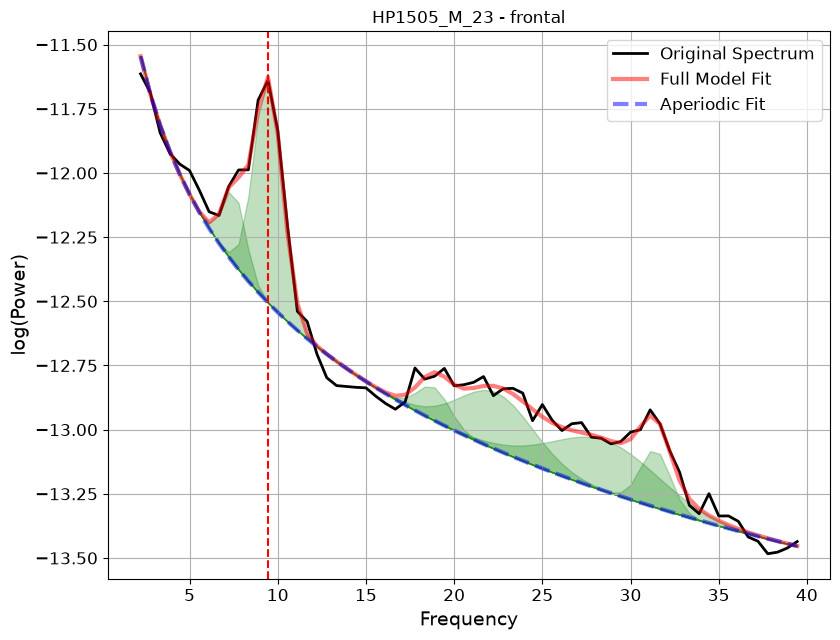

HZ1304_F_29 | frontal | IAF=nan | status=weak_peak
IZ2310_F_21 | frontal | IAF=11.08 | status=FOOOF


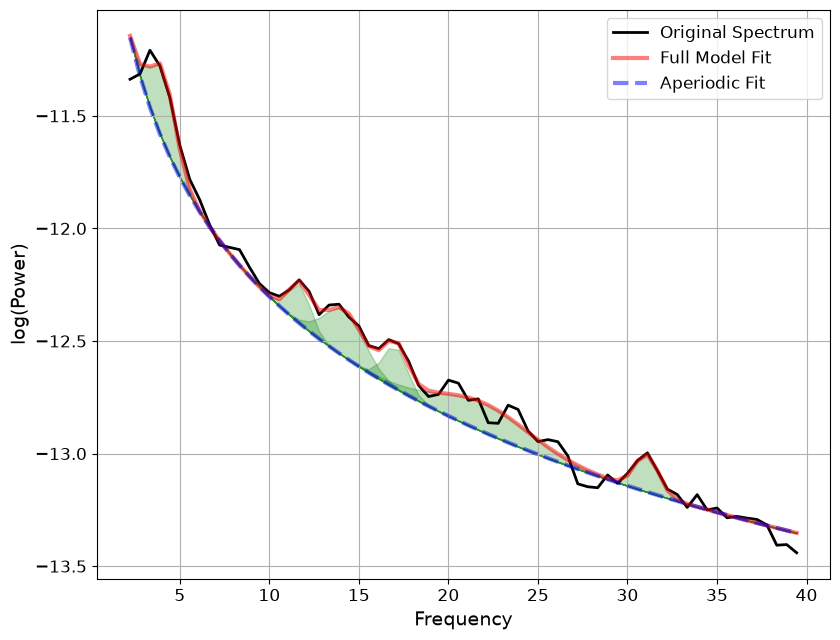

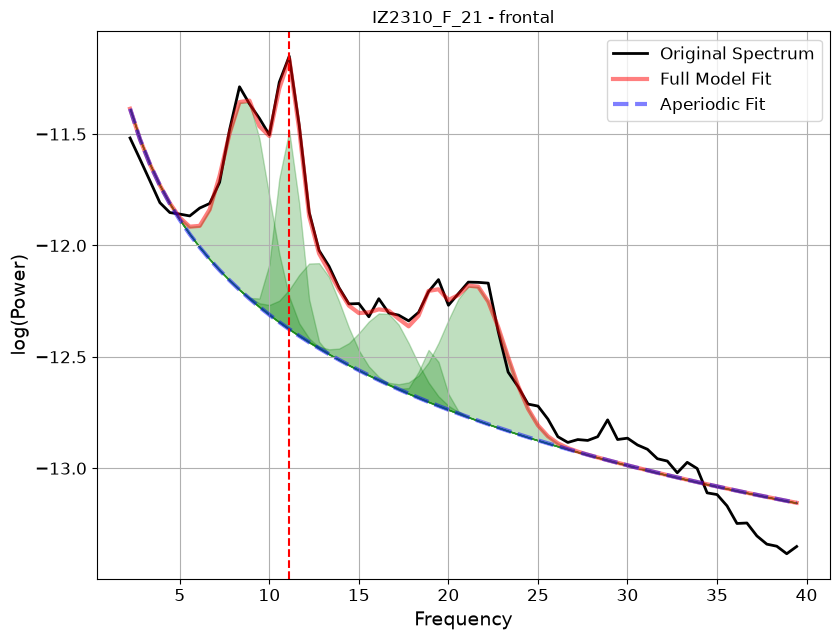

JA0310_F_20 | frontal | IAF=nan | status=weak_peak
JB0612_F_20 | frontal | IAF=10.85 | status=FOOOF


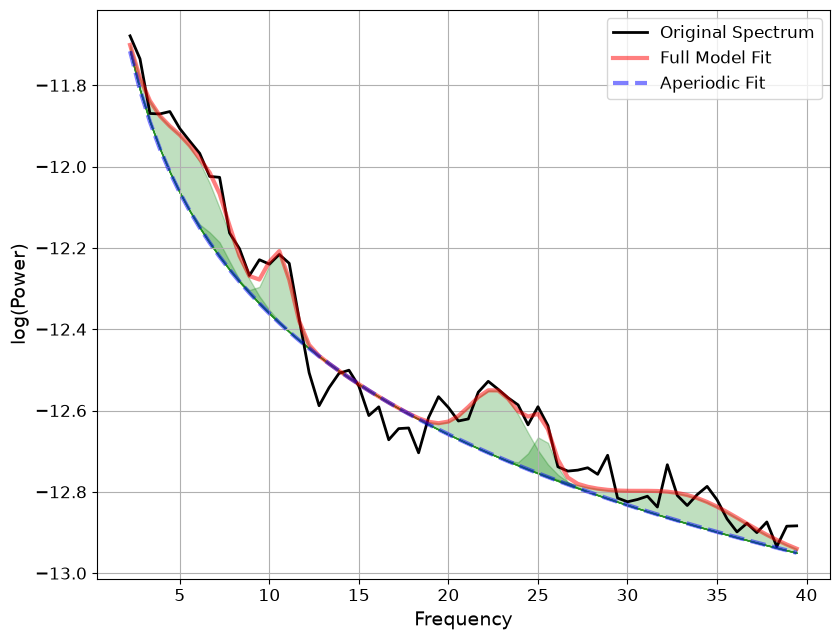

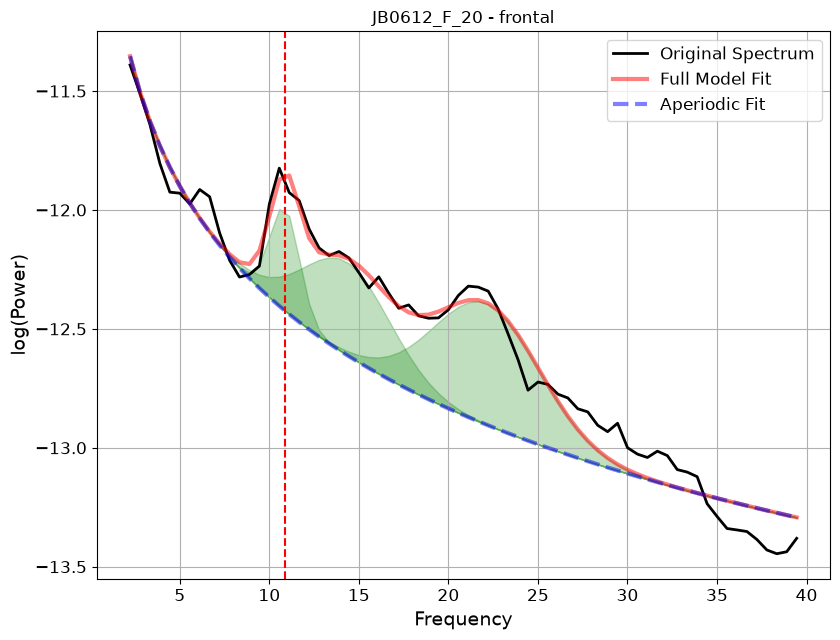

HP1505_M_23 | posterior | IAF=9.43 | status=FOOOF


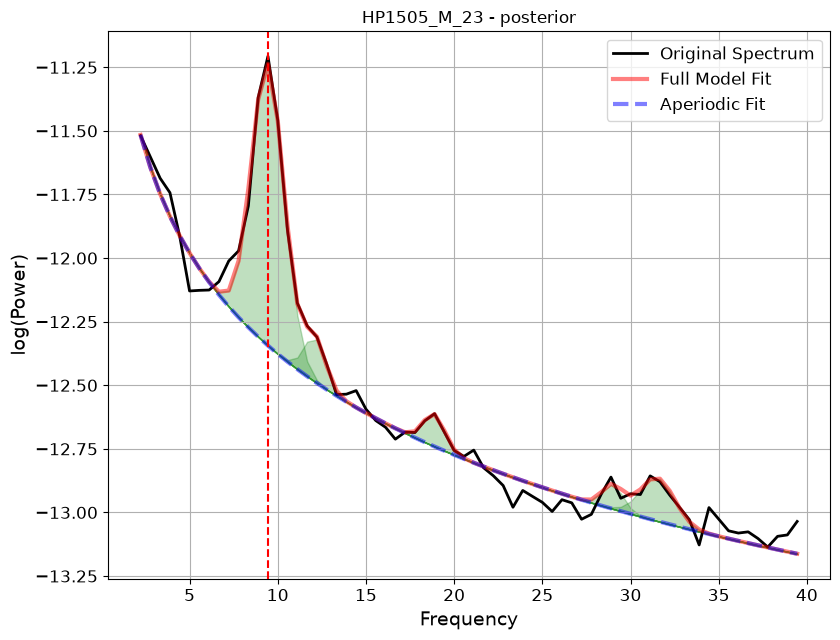

HZ1304_F_29 | posterior | IAF=nan | status=edge_peak
IZ2310_F_21 | posterior | IAF=11.03 | status=FOOOF


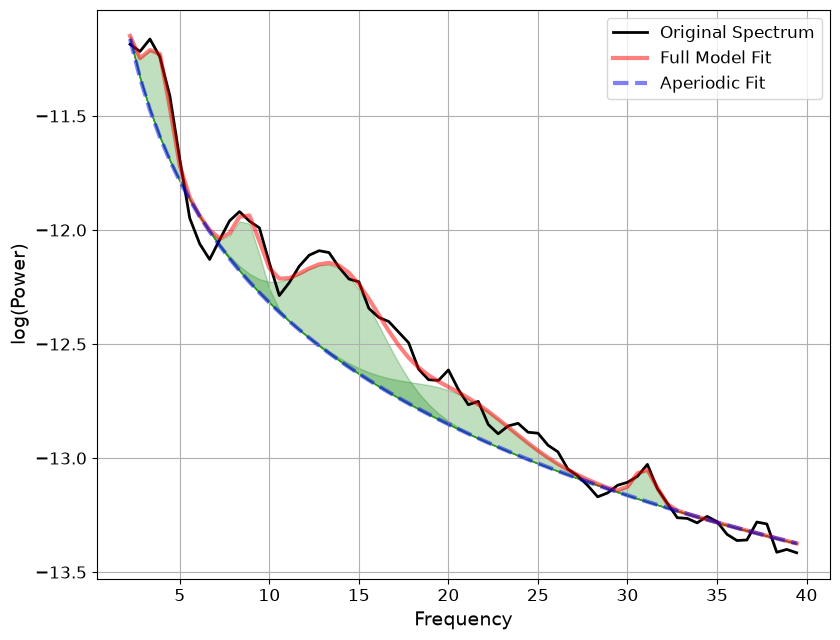

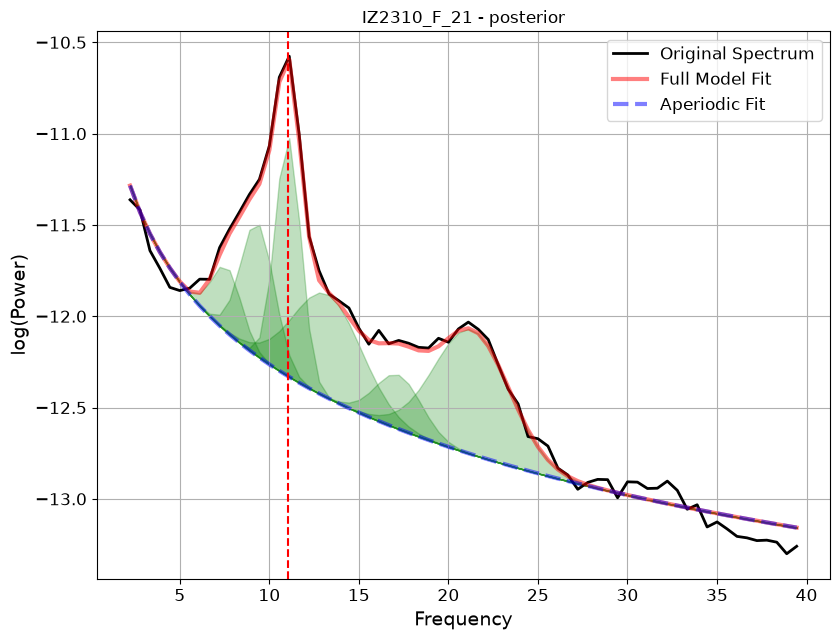

JA0310_F_20 | posterior | IAF=11.12 | status=FOOOF


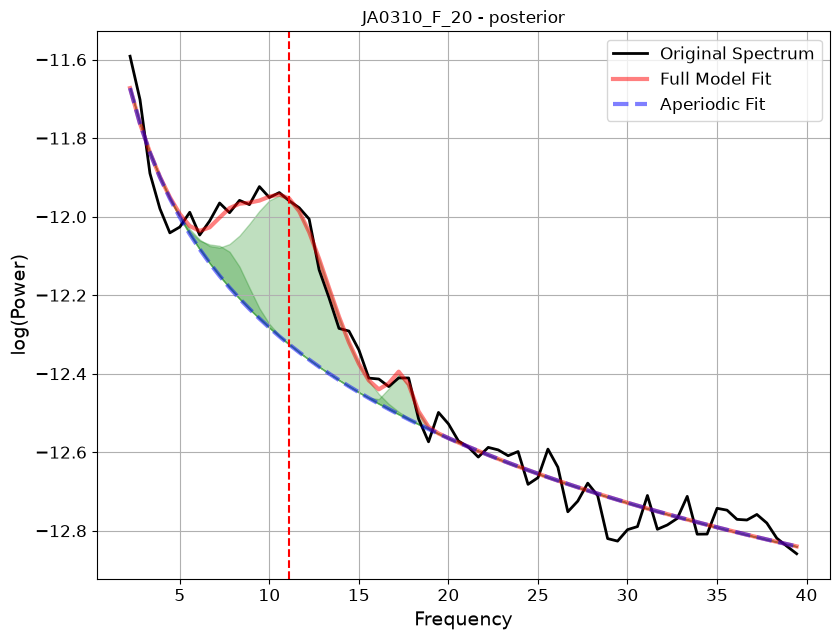

JB0612_F_20 | posterior | IAF=10.73 | status=FOOOF


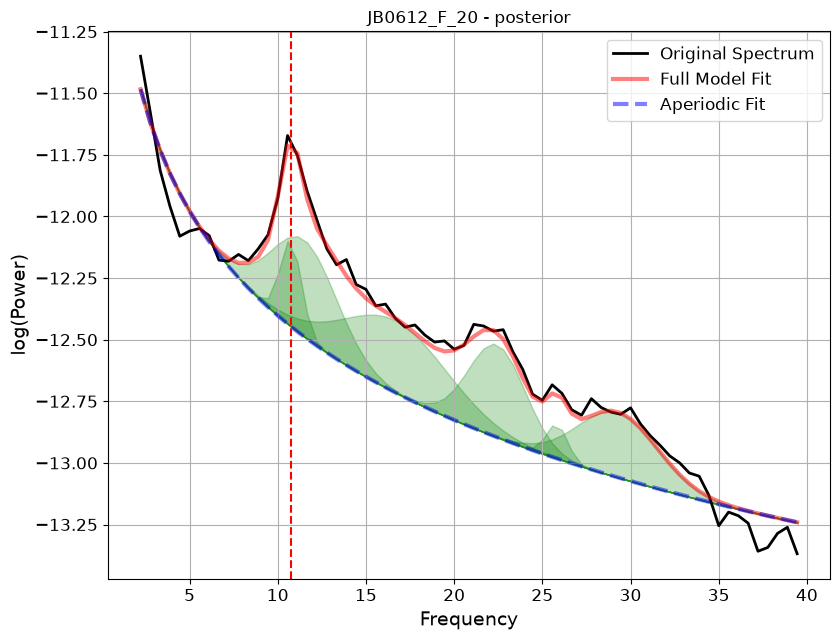


Analysis complete.
Results saved to: /Users/Emila/Desktop/SONATA21/IAF_WPR/IAF_results


In [16]:
#PROCESSING FILES
epoch_files = sorted(
    set(DATA_DIR.rglob("*-epo.fif"))
    | set(DATA_DIR.rglob("*_epo.fif"))
)

if not epoch_files:
    raise FileNotFoundError(
        f"No epochs files found in {DATA_DIR.resolve()}"
    )

results = []

for file_path in epoch_files:
    region_name = file_path.parent.name.lower()

    if region_name not in REGIONS:
        continue

    subject_id = get_subject_id(file_path)

    epochs = mne.read_epochs(
        file_path,
        preload=True,
        verbose=False,
    )

    freqs, psd, used_channels = calculate_roi_psd(
        epochs,
        REGIONS[region_name],
    )

    if freqs is None:
        print(f"Skipping {subject_id} ({region_name}): no usable ROI channels.")
        continue

    res, fm = estimate_iaf(freqs, psd)
    iaf = res["IAF"]
    print(f"{subject_id} | {region_name} | IAF={iaf:.2f} | status={res['status']}")

    fm.plot(plot_peaks="shade")            # log spectrum + model, easier to judge
    if np.isfinite(iaf):
        plt.axvline(iaf, color="red", ls="--")
        plt.title(f"{subject_id} - {region_name}")
        plt.show()

    results.append({"subject_id": subject_id, "region": region_name,
                "n_epochs": len(epochs), "n_channels": len(used_channels), **res})

#SAVING RESULTS
if not results:
    raise RuntimeError("No results were produced. Check the input files and folders.")

results_df = pd.DataFrame(results)

results_df.to_csv(
    OUTPUT_DIR / "IAF_all_subjects_long.csv",
    index=False,
)

if not results_df.duplicated(["subject_id", "region"]).any():
    wide_df = results_df.pivot(
        index="subject_id",
        columns="region",
        values="IAF",
    ).reset_index()

    wide_df.to_csv(
        OUTPUT_DIR / "IAF_two_regions.csv",
        index=False,
    )

print("\nAnalysis complete.")
print(f"Results saved to: {OUTPUT_DIR.resolve()}")

In [17]:
print(results_df[["subject_id", "region", "IAF", "alpha_height_log10", "status"]]
      .sort_values("alpha_height_log10")
      .to_string(index=False))

 subject_id    region       IAF  alpha_height_log10    status
JA0310_F_20   frontal       NaN            0.176665 weak_peak
HZ1304_F_29   frontal       NaN            0.187732 weak_peak
JA0310_F_20 posterior 11.117465            0.371649     FOOOF
HZ1304_F_29 posterior       NaN            0.415254 edge_peak
JB0612_F_20   frontal 10.849746            0.583343     FOOOF
JB0612_F_20 posterior 10.726493            0.722686     FOOOF
HP1505_M_23   frontal  9.456751            0.878494     FOOOF
HP1505_M_23 posterior  9.432451            1.108077     FOOOF
IZ2310_F_21   frontal 11.081471            1.214190     FOOOF
IZ2310_F_21 posterior 11.032036            1.738203     FOOOF
